# Exercise 1 

In this exercise, we will practice how to read error messages in Python.

### Exercise 1(a) (2 points)

Load the `pandas` library.

In [1]:
import pandas as pd

### Exercise 1(b) (3 points)

Consider the below dictionary

```
data = {'x': ['1', '3.3', 4, '6.8', 10],
        'y': [3.2, 1.8, 8.5, 4.4, 5.3]}
```

Using the `data` dictionary, create a data frame called `df`

In [2]:
data = {
    'x': ['1', '3.3', 4, '6.8', 10],
    'y': [3.2, 1.8, 8.5, 4.4, 5.3]
}

df = pd.DataFrame(data)
df

,x,y
0,1,3.2
1,3.3,1.8
2,4,8.5
3,6.8,4.4
4,10,5.3


### Exercise 1(c) (4 points)

Compute the average of the values in each row and store the result in a new column labeled `z`.

In [3]:
df['z'] = (df['x'] + df['y']) / 2

<class 'TypeError'>: can only concatenate str (not "float") to str

### Exercise 1(d) (5 points)

Print `.info()` of `df`, and modify `df` to compute the mean of row values.

In [4]:
df.info()

df['x'] = pd.to_numeric(df['x'])

df['z'] = df[['x', 'y']].mean(axis=1)

print(df)

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       5 non-null      object 
 1   y       5 non-null      float64
dtypes: float64(1), object(1)
memory usage: 132.0+ bytes
      x    y     z
0   1.0  3.2  2.10
1   3.3  1.8  2.55
2   4.0  8.5  6.25
3   6.8  4.4  5.60
4  10.0  5.3  7.65


# Exercise 2

In this exercise, we will practice data visualiation with the `tips.csv` data file.

### Exercise 2(a) (2 points)

Load `pandas` and `matplotlib`.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

### Exercise 2(b) (2 points)

Read the `tips.csv` data file and create a data frame called `tips`.

In [6]:
tips = pd.read_csv('tips.csv')
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


### Exercise 2(c) (4 points)

Create a histogram of `total_bill`. Comment on the shape of the distributions.

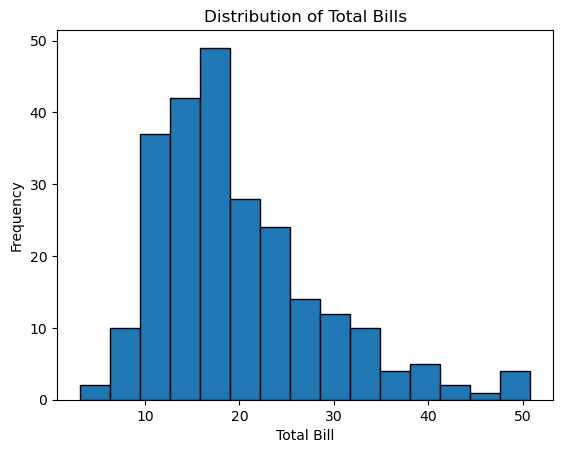

In [7]:
plt.hist(tips['total_bill'], bins=15, edgecolor='black')
plt.xlabel('Total Bill')
plt.ylabel('Frequency')
plt.title('Distribution of Total Bills')
plt.show()

### Exercise 2(d) (5 points)

Create a side-by-side boxplot of `total_bill` based on the day of the week.

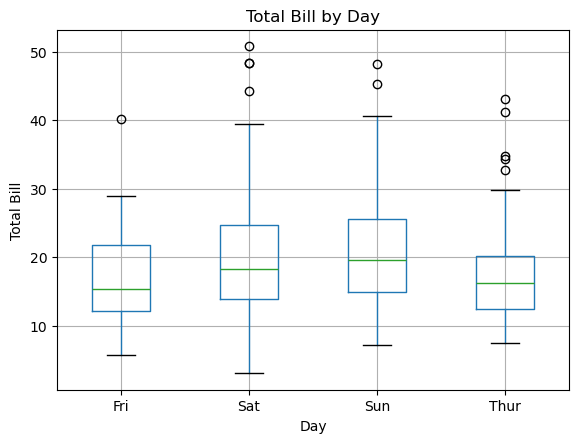

In [8]:
tips.boxplot(column='total_bill', by='day')

plt.title('Total Bill by Day')
plt.suptitle('')
plt.xlabel('Day')
plt.ylabel('Total Bill')
plt.show()

### Exercise 2(e) (5 points)

Create a scatter-plot of `total_bill` and `tip`. Describe the plot.

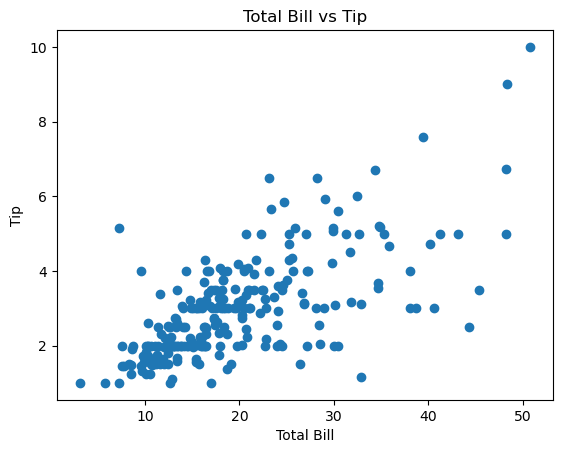

In [9]:
plt.scatter(tips['total_bill'], tips['tip'])

plt.xlabel('Total Bill')
plt.ylabel('Tip')
plt.title('Total Bill vs Tip')
plt.show()

# Exercise 3

In this exercise, we will practice debugging a data cleaning script written for the `tips.csv` data file. A colleague wrote the code below to compute the tip percentage (`tip` divided by `total_bill`, times 100) and compare it across days, but it contains several bugs.

```
import pandas as pd

tips = pd.read_csv('tips.csv')

# Step 1: tip percentage
tips['tip_pct'] = tips['tip'] / tips['Total_Bill'] * 100

# Step 2: average tip percentage by day
avg_by_day = tips.groupby('day')['tip_pct'].mean()
print('Average tip % on Saturday: ' + avg_by_day['Sat'])

# Step 3: weekend orders only
weekend = tips[(tips['day'] == 'Sat') or (tips['day'] == 'Sun')]
print(weekend.shape)
```

### Exercise 3(a) (4 points)

Run Step 1 in the cell below. Read the error message: what type of error is it, which line causes it, and why? Fix the code so that it runs.

In [11]:
tips['tip_pct'] = tips['tip'] / tips['total_bill'] * 100

### Exercise 3(b) (4 points)

Run Step 2. Read the error message, explain what went wrong, and fix the code so that it prints the average tip percentage on Saturday rounded to two decimals.

In [12]:
avg_by_day = tips.groupby('day')['tip_pct'].mean()

print(f"Average tip % on Saturday: {avg_by_day['Sat']:.2f}")

Average tip % on Saturday: 15.32


### Exercise 3(c) (4 points)

Run Step 3. Read the error message, explain what went wrong, and fix the code so that `weekend` contains only the Saturday and Sunday orders.

In [13]:
weekend = tips[tips['day'].isin(['Sat', 'Sun'])]

print(weekend.shape)

(163, 8)


### Exercise 3(d) (4 points)

Not every bug raises an error. Use `.describe()` on `tip_pct` and `.isna().sum()` on `tips` to check that your results are reasonable (for example, tip percentages should be between 0 and 100 and there should be no missing values). Then use an `assert` statement to verify that `weekend` contains only `'Sat'` and `'Sun'`. Summarize what you found.

In [14]:
print(tips['tip_pct'].describe())

print(tips.isna().sum())

assert weekend['day'].isin(['Sat', 'Sun']).all()

print("All weekend orders are from Saturday or Sunday.")

count    244.000000
mean      16.080258
std        6.107220
min        3.563814
25%       12.912736
50%       15.476977
75%       19.147549
max       71.034483
Name: tip_pct, dtype: float64
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
tip_pct       0
dtype: int64
All weekend orders are from Saturday or Sunday.
